# 04 – Model comparison

Does a non-linear model (XGBoost) add value over the logistic regression once the data is well prepared?
Models are compared with 5-fold stratified cross-validation on the training set, then evaluated once on the test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from scipy.stats import ks_2samp
from xgboost import XGBClassifier

In [2]:
train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

target = "SeriousDlqin2yrs"
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

print(X_train.shape, X_test.shape, len(y_train), len(y_test))

(119999, 14) (30000, 14) 119999 30000


In [3]:
def evaluar(nombre, y_real, pd_estimada):
    """Discrimination and calibration metrics for a PD model."""
    auc = roc_auc_score(y_real, pd_estimada)
    ks = ks_2samp(pd_estimada[y_real == 1], pd_estimada[y_real == 0]).statistic
    return {
        "Model": nombre,
        "AUC": round(auc, 4),
        "Gini": round(2 * auc - 1, 4),
        "KS": round(ks, 4),
        "Brier": round(brier_score_loss(y_real, pd_estimada), 4),
        "Avg PD": round(pd_estimada.mean(), 4),
    }

## 1. Models

In [4]:
modelos = {
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42),
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
}

## 2. Stratified 5-fold cross-validation (training set)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados_cv = []
for nombre, modelo in modelos.items():
    scores = cross_validate(
        modelo, X_train, y_train, cv=cv,
        scoring={"AUC": "roc_auc", "Brier": "neg_brier_score"},
    )
    resultados_cv.append({
        "Model": nombre,
        "AUC mean": scores["test_AUC"].mean().round(4),
        "AUC std": scores["test_AUC"].std().round(4),
        "Brier mean": (-scores["test_Brier"]).mean().round(4),
    })
    print(nombre, "listo")

pd.DataFrame(resultados_cv)

Logistic regression listo
XGBoost listo


,Model,AUC mean,AUC std,Brier mean
0,Logistic regression,0.8518,0.0065,0.0510
1,XGBoost,0.8647,0.0057,0.0491


## 3. Final evaluation on the test set

In [6]:
pds = {}
resultados_test = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pds[nombre] = modelo.predict_proba(X_test)[:, 1]
    resultados_test.append(evaluar(nombre, y_test, pds[nombre]))

pd.DataFrame(resultados_test)

,Model,AUC,Gini,KS,Brier,Avg PD
0,Logistic regression,0.8593,0.7186,0.5619,0.0507,0.0671
1,XGBoost,0.8695,0.7389,0.5847,0.0487,0.0669


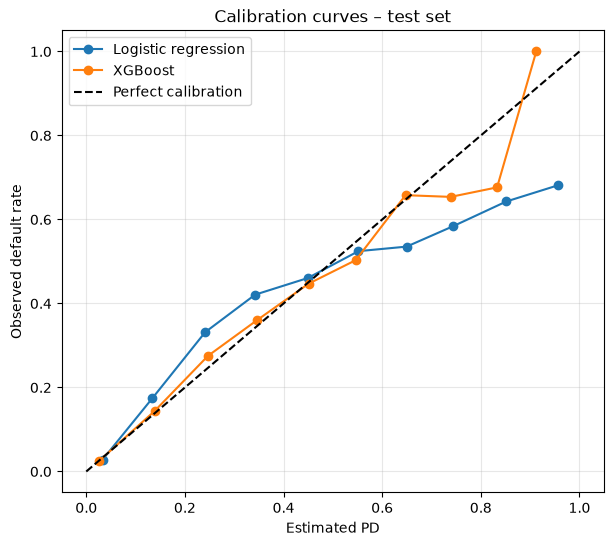

In [7]:
plt.figure(figsize=(7, 6))

for nombre, pd_est in pds.items():
    frac_real, prob_media = calibration_curve(y_test, pd_est, n_bins=10)
    plt.plot(prob_media, frac_real, marker="o", label=nombre)

plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Estimated PD")
plt.ylabel("Observed default rate")
plt.title("Calibration curves – test set")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/calibration_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
conteo, _ = np.histogram(pds["XGBoost"], bins=10, range=(0, 1))
pd.DataFrame({"PD range": [f"{i/10:.1f}-{(i+1)/10:.1f}" for i in range(10)],
              "Borrowers": conteo})

,PD range,Borrowers
0,0.0-0.1,25127
1,0.1-0.2,2354
2,0.2-0.3,839
3,0.3-0.4,603
4,0.4-0.5,407
5,0.5-0.6,302
6,0.6-0.7,228
7,0.7-0.8,104
8,0.8-0.9,34
9,0.9-1.0,2


In [9]:
calibration_curve(y_test, pd_est, n_bins=10, strategy="quantile")

(array([0.00366667, 0.00666667, 0.00866667, 0.01066667, 0.017     ,
        0.02133333, 0.039     , 0.072     , 0.11466667, 0.37466667]),
 array([0.00488809, 0.00724193, 0.00979693, 0.01304078, 0.01828873,
        0.02702224, 0.04112414, 0.06518341, 0.11373818, 0.36885431]))

## Conclusions

**XGBoost outperforms the logistic regression on both discrimination and calibration.**

| Model | CV AUC (mean ± std) | Test AUC | Gini | KS | Brier | Avg PD |
|---|---|---|---|---|---|---|
| Logistic regression | 0.852 ± 0.007 | 0.859 | 0.719 | 0.562 | 0.0507 | 6.71% |
| **XGBoost** | **0.865 ± 0.006** | **0.870** | **0.739** | **0.585** | **0.0487** | 6.69% |

*Observed default rate in the test set: 6.68%.*

- **Discrimination:** XGBoost has a higher AUC (0.870 vs. 0.859) and also outperforms on Gini and KS. Cross-validation confirms that the gap is stable across folds, not the result of a lucky split.
- **Calibration:** XGBoost has a lower Brier score (0.0487 vs. 0.0507). Both models predict an average PD almost equal to the observed default rate, which comes from training without SMOTE.
- **Calibration curves:** XGBoost follows the diagonal up to a PD of ~0.65 and corrects the S-shape of the logistic regression, which underestimates risk between 10% and 45%. Above 0.7 the curve is noisy because very few borrowers fall in those bins.
- **Versus the original thesis:** with the same algorithm, XGBoost goes from an AUC of 0.832 to 0.870 and from a Brier score of 0.0657 to 0.0487 (−26%), thanks to the new data preparation and removing SMOTE.
- **Trade-off:** the logistic regression remains easier to explain to regulators (one coefficient per variable), while XGBoost captures non-linear effects such as the jump in risk above 70% utilization. SHAP values (notebook 05) will be used to explain it.